# HeatCity — análise reproduzível do detector de placas

**CitizenTech:** apoiar a revisão de sinalização para pacientes, acompanhantes e visitantes de espaços coletivos. O operador usa câmera e dados para levantar hipóteses de visibilidade; a pessoa beneficiada não precisa instalar o sistema.

Este notebook usa o MP4 sintético versionado, suas posições geométricas conhecidas e as saídas do detector. **Não há entrevistas, participantes ou impacto humano demonstrado neste ensaio.** O objetivo é conferir as métricas e as falhas, sem treinamento de modelo.

Entradas disponíveis no checkout: `frontend/public/detection-demo.mp4`, `frontend/public/detection-demo.json` e `docs/reports/deteccao-placas-benchmark.json`. Reexecutar após regenerar o benchmark atualiza as saídas.

In [1]:
from pathlib import Path
import json, hashlib, html
from collections import Counter, defaultdict
from IPython.display import display, Markdown, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'backend/heatcity').is_dir())
benchmark = json.loads((root / 'docs/reports/deteccao-placas-benchmark.json').read_text())
truth = json.loads((root / 'frontend/public/detection-demo.json').read_text())
video_sha = hashlib.sha256((root / 'frontend/public/detection-demo.mp4').read_bytes()).hexdigest()
assert video_sha == benchmark['video_sha256'], 'O vídeo diverge das medições.'
print('SHA-256 do vídeo conferido:', video_sha)
print('Quadros:', len(benchmark['frames']))
print('Runtime do detector:', benchmark['runtime'])

SHA-256 do vídeo conferido: 941470ccda3b6a5669bacb0a80a5968205bfbefcab5557d0b66589146e69cbb4
Quadros: 24
Runtime do detector: {'python': '3.12.14', 'opencv': '5.0.0', 'numpy': '2.3.5'}


## Recalcular a partir das caixas e da referência conhecida

A contagem abaixo não importa as funções de métricas do backend. TP exige identidade correta, decisão `detected` e IoU ≥ 0,5. Uma localização positiva incorreta gera FP e FN. Se a placa está presente mas a decisão é incerta ou ausente, gera FN. Placas ausentes e decisão `not_found` geram TN. Não se elimina o desfoque do denominador.

In [2]:
def overlap(a, b):
    if a is None: return 0.0
    width = max(0.0, min(a[0]+a[2], b[0]+b[2]) - max(a[0], b[0]))
    height = max(0.0, min(a[1]+a[3], b[1]+b[3]) - max(a[1], b[1]))
    intersection = width*height
    return intersection / max(1e-12, a[2]*a[3]+b[2]*b[3]-intersection)
counts = Counter()
by_condition = defaultdict(Counter)
ious = []
for frame in benchmark['frames']:
    segment = next(s for s in truth['segments'] if s['start'] <= frame['time'] < s['end'])
    signs = {s['name']:s for s in frame['signs']}
    for annotation in segment['annotations']:
        result = signs[annotation['name']]
        positive = result['status'] == 'detected'
        c = Counter(annotations=1)
        if annotation['present']:
            value = overlap(result['box'], annotation['box'])
            ious.append(value)
            if positive and value >= 0.5: c['tp'] += 1
            else:
                c['fn'] += 1
                if positive: c['fp'] += 1
        elif positive: c['fp'] += 1
        elif result['status'] == 'not_found': c['tn'] += 1
        if result['status'] in ('ambiguous','conflict'): c['abstentions'] += 1
        counts.update(c)
        by_condition[segment['condition']].update(c)
for key in ('tp','fp','fn','tn','annotations','abstentions'):
    assert counts[key] == benchmark['summary'][key], key
precision = counts['tp']/(counts['tp']+counts['fp']) if counts['tp']+counts['fp'] else None
recall = counts['tp']/(counts['tp']+counts['fn']) if counts['tp']+counts['fn'] else None
mean_iou = sum(ious)/len(ious)
assert abs(precision-benchmark['summary']['precision']) < 1e-10
assert abs(recall-benchmark['summary']['recall']) < 1e-10
assert abs(mean_iou-benchmark['summary']['mean_iou']) < 1e-10
display(Markdown('| TP | FP | FN | TN | Anotações | Precisão | Recall | IoU médio |\n|---:|---:|---:|---:|---:|---:|---:|---:|\n' + f"| {counts['tp']} | {counts['fp']} | {counts['fn']} | {counts['tn']} | {counts['annotations']} | {precision:.3f} | {recall:.3f} | {mean_iou:.3f} |"))
print('Contagens e métricas conferem com as saídas versionadas.')

| TP | FP | FN | TN | Anotações | Precisão | Recall | IoU médio |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 66 | 0 | 24 | 6 | 96 | 1.000 | 0.733 | 0.714 |

Contagens e métricas conferem com as saídas versionadas.


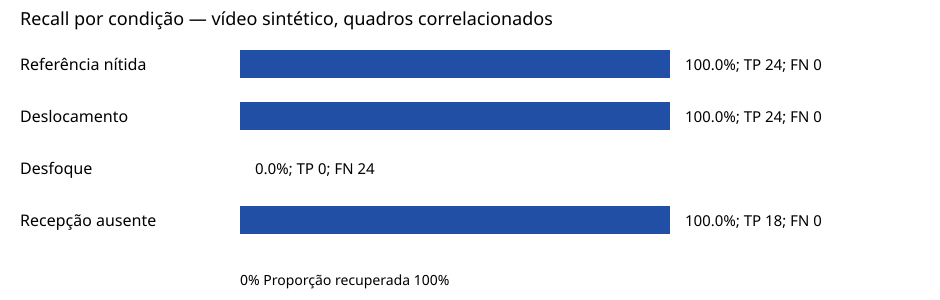

In [3]:
names = {'referencia_nitida':'Referência nítida','deslocamento':'Deslocamento','desfoque':'Desfoque','recepcao_ausente':'Recepção ausente'}
svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="940" height="300" viewBox="0 0 940 300">', '<rect width="940" height="300" fill="white"/>', '<text x="20" y="25" font-family="sans-serif" font-size="18">Recall por condição — vídeo sintético, quadros correlacionados</text>']
for index, (condition,c) in enumerate(by_condition.items()):
    value = c['tp']/(c['tp']+c['fn']) if c['tp']+c['fn'] else 0
    y = 50+index*52
    svg += [f'<text x="20" y="{y+20}" font-family="sans-serif" font-size="16">{html.escape(names[condition])}</text>', f'<rect x="240" y="{y}" width="{value*430}" height="28" fill="#214fa6"/>', f'<text x="{255+value*430}" y="{y+20}" font-family="sans-serif" font-size="15">{value:.1%}; TP {c["tp"]}; FN {c["fn"]}</text>']
svg.append('<text x="240" y="285" font-family="sans-serif" font-size="14">0%                                      Proporção recuperada                                      100%</text></svg>')
display(SVG(''.join(svg)))

## Discussão e limites

- Precisão 1,000 não significa detecção perfeita: o recall inclui as detecções perdidas, inclusive sob desfoque.
- A condição com ausência da Recepção mede também a abstenção de detectar o alvo removido; o recall daquela condição considera apenas placas presentes.
- Os 24 quadros são correlacionados e derivam da mesma fotografia de IA usada como referência. Não são participantes independentes nem evidência de generalização.
- Tempo detectado é uma estimativa entre amostras consecutivas, não prova presença contínua ou leitura humana.
- Indícios de nitidez, contraste e correspondências semelhantes apoiam hipóteses de captura/posicionamento, sem determinar uma causa ou altura ideal.

## CitizenTech e próximos passos reais

Beneficiários propostos: pacientes, acompanhantes e visitantes. Operadores: responsáveis pela sinalização e manutenção do espaço. Benefício esperado: tornar placas mais fáceis de localizar no percurso; isso **ainda não foi medido com pessoas**.

ODS propostos: **3, meta 3.8**, por apoiar o acesso à orientação em serviços de saúde; **11, meta 11.7**, pela intenção de espaços de uso coletivo mais acessíveis. São contribuições indiretas a verificar, não metas demonstradas pelo benchmark.

Próximas evidências: observação/relato real com consentimento, captura real anotada e teste antes/depois com pessoas, medindo tempo de localização, enganos e pedidos de ajuda. Não há resultados inventados para essas etapas.